# Reconocimiento de dígitos escritos: Evaluación y conclusiones

Ejecuta la etapa anterior primero. Las cifras y conclusiones siguientes se calculan con los datos de esta ejecución; no edites manualmente sus valores. Consulta [metodología](../docs/metodologia.md) para interpretar resultados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("digits_recognition")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from digits_recognition.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Reconocimiento de dígitos escritos: evaluacion

Test: **360 imágenes**; accuracy **98.33%**, F1 macro **0.9833** frente a **0.8578** del baseline. Al desplazar artificialmente un píxel a la derecha, la accuracy es **31.11%**. Este ensayo describe sensibilidad a una perturbación concreta, no robustez general ni una evaluación en documentos reales. No se seleccionan parámetros a partir de test.


,casos,accuracy,f1_macro
baseline,360.0,0.858333,0.857843
modelo,360.0,0.983333,0.983262


,precision,recall,f1-score,support
0,1.000000,1.000000,1.000000,35.000000
1,0.972973,0.972973,0.972973,37.000000
2,1.000000,0.971429,0.985507,35.000000
3,0.973684,1.000000,0.986667,37.000000
4,0.921053,0.972222,0.945946,36.000000
5,1.000000,1.000000,1.000000,37.000000
6,1.000000,1.000000,1.000000,36.000000
7,0.972973,1.000000,0.986301,36.000000
8,1.000000,0.914286,0.955224,35.000000
9,1.000000,1.000000,1.000000,36.000000


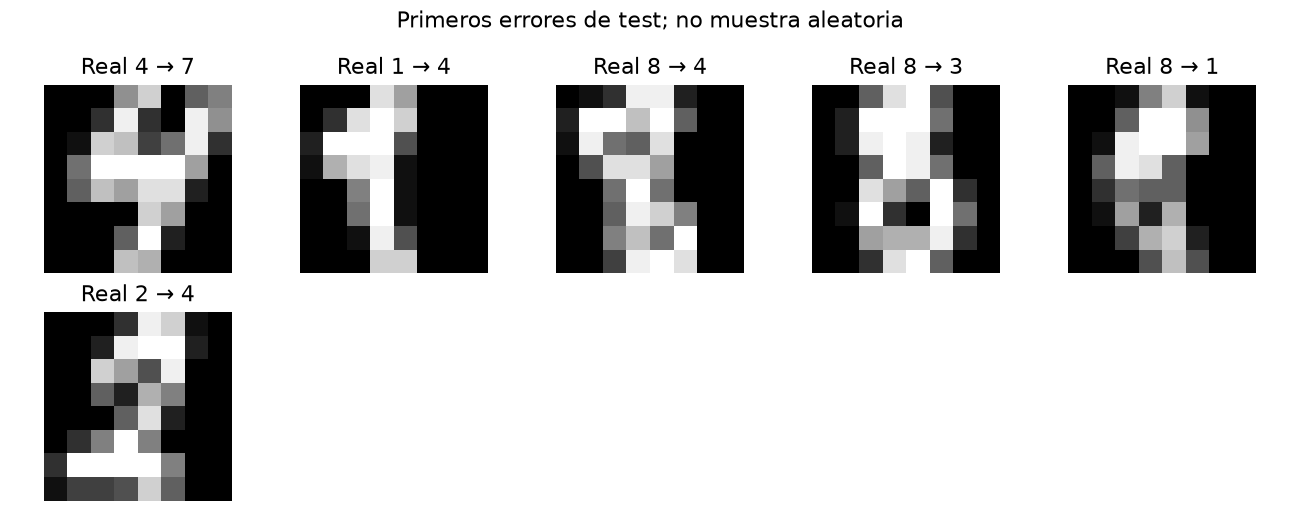

In [2]:
from digits_recognition.analysis import run_stage
import pandas as pd
metrics, comment = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comment))
scalars = {k: v for k, v in metrics.items() if not isinstance(v, (dict, list))}
if scalars:
    display(pd.DataFrame(list(scalars.items()), columns=["Indicador", "Valor"]))
if "candidatos" in metrics:
    display(pd.DataFrame(metrics["candidatos"]))
if "baseline" in metrics and "modelo" in metrics:
    comparison = {key: {k: v for k, v in metrics[key].items() if not isinstance(v, (dict, list))} for key in ["baseline", "modelo"]}
    display(pd.DataFrame(comparison).T)
if "clasificacion" in metrics.get("modelo", {}):
    display(pd.DataFrame(metrics["modelo"]["clasificacion"]).T)
for image_name in ["eda.png", "evaluacion.png"]:
    image_path = PROJECT_ROOT / "reports/evaluacion" / image_name
    if image_path.exists():
        display(Image(filename=str(image_path)))


In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from digits_recognition.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))


[Abrir informe integral](../reports/informe_final/informe_final.md)